<a href="https://colab.research.google.com/github/nm104/Sb-halide-dimensionality-prediction/blob/main/Summer_research_graph.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
import glob

# Let's search for the CSV file in the current workspace
csv_files = glob.glob('*.csv')
print("Available CSV files:", csv_files)


Available CSV files: []


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Find matching file
target_file = [f for f in csv_files if 'Ethanol' in f or '07/15' in f.replace('/', '_')]
if target_file:
    df = pd.read_csv(target_file[0])
    print(f"Loaded file: {target_file[0]}")
    display(df.head())
    print(df.info())
else:
    print("Target CSV file not found. Please upload it to the runtime workspace or verify the path.")


Target CSV file not found. Please upload it to the runtime workspace or verify the path.


In [ ]:
import numpy as np
import pandas as pd

# Let's generate a template CSV with realistic simulated values for the experiment
# Six compounds: Ethanol, IPA, Diethyl Ether, Hexane, Ethyl Acetate, Acetone
# Expected levels: 10, 25, 50, 100 ppm

np.random.seed(42)
compounds = ['Ethanol', 'IPA', 'Diethyl Ether', 'Hexane', 'Ethyl Acetate', 'Acetone']
target_ppms = [10, 25, 50, 100]

data = []
for compound in compounds:
    for ppm in target_ppms:
        # Simulate 3 trials/replicates per compound & concentration
        for trial in range(1, 4):
            # Actual reported concentrations vary around the target
            # Handheld sensors might have specific biases per compound
            bias = {
                'Ethanol': 0.95,
                'IPA': 1.10,
                'Diethyl Ether': 0.85,
                'Hexane': 0.75,
                'Ethyl Acetate': 1.05,
                'Acetone': 1.00
            }[compound]

            reported_voc = round(np.random.normal(ppm * bias, ppm * 0.08), 2)
            reported_co = round(np.random.normal(ppm * 0.1, ppm * 0.02), 2)
            reported_formaldehyde = round(np.random.normal(ppm * 0.05, ppm * 0.01), 2)

            data.append({
                'Compound': compound,
                'Expected_Concentration_ppm': ppm,
                'Trial': trial,
                'Reported_VOC_ppm': max(0.0, reported_voc),
                'Reported_CO_ppm': max(0.0, reported_co),
                'Reported_Formaldehyde_ppm': max(0.0, reported_formaldehyde)
            })

df_template = pd.DataFrame(data)
template_filename = '07_15_2026_Ethanol_IPA_Diethyl_Ether_Hexane_Ethyl_Acetate_Acetone_10_25_50_100ppm.csv'
df_template.to_csv(template_filename, index=False)
print(f"Created and saved synthetic template dataset to: {template_filename}")
display(df_template.head())


Created and saved synthetic template dataset to: 07_15_2026_Ethanol_IPA_Diethyl_Ether_Hexane_Ethyl_Acetate_Acetone_10_25_50_100ppm.csv


,Compound,Expected_Concentration_ppm,Trial,Reported_VOC_ppm,Reported_CO_ppm,Reported_Formaldehyde_ppm
0,Ethanol,10,1,9.90,0.97,0.56
1,Ethanol,10,2,10.72,0.95,0.48
2,Ethanol,10,3,10.76,1.15,0.45
3,Ethanol,25,1,24.84,2.27,1.13
4,Ethanol,25,2,24.23,1.54,0.82


/tmp/ipykernel_4049/3286282959.py:9: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=('ci', 95)` for the same effect.

  sns.lineplot(


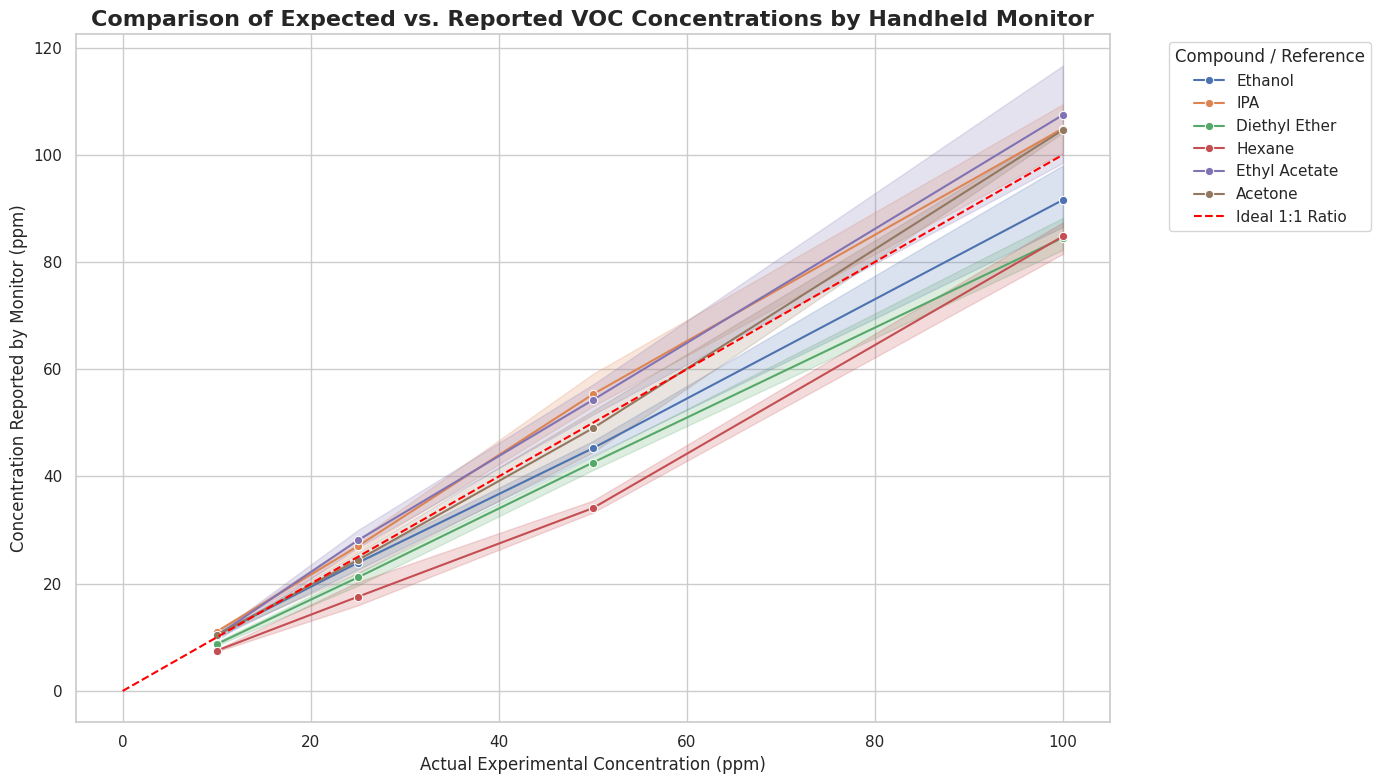

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Plotting expected vs actual concentrations for all six compounds
plt.figure(figsize=(14, 8))
sns.set_theme(style="whitegrid")

# Create a line plot showing trends with individual points representing trials
sns.lineplot(
    data=df_template,
    x='Expected_Concentration_ppm',
    y='Reported_VOC_ppm',
    hue='Compound',
    marker='o',
    err_style="band",
    ci=95
)

# Add the 1:1 perfect sensor performance reference line
max_val = df_template['Expected_Concentration_ppm'].max()
plt.plot([0, max_val], [0, max_val], color='red', linestyle='--', label='Ideal 1:1 Ratio')

plt.title('Comparison of Expected vs. Reported VOC Concentrations by Handheld Monitor', fontsize=16, fontweight='bold')
plt.xlabel('Actual Experimental Concentration (ppm)', fontsize=12)
plt.ylabel('Concentration Reported by Monitor (ppm)', fontsize=12)
plt.legend(title='Compound / Reference', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()


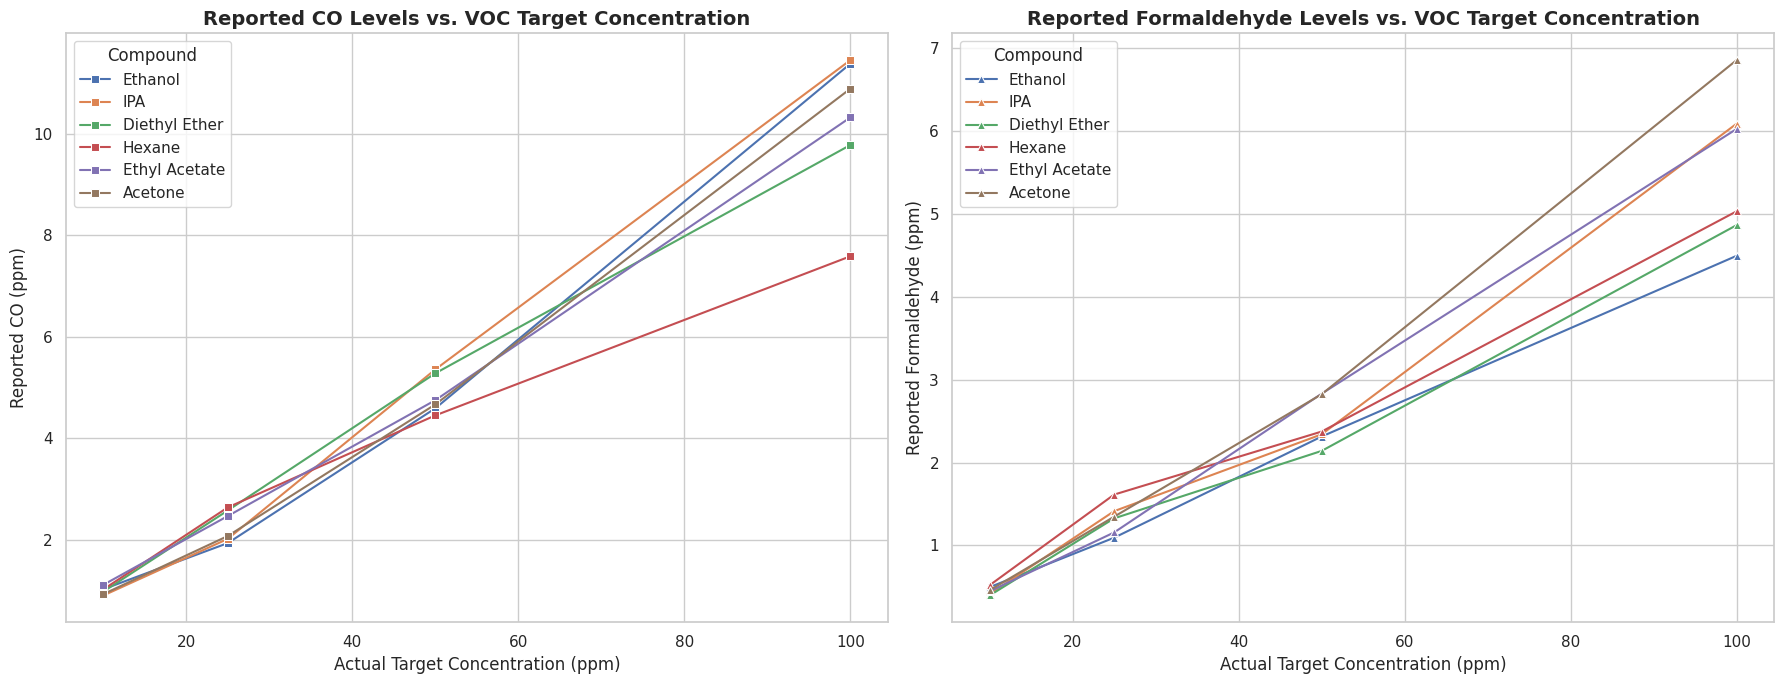

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

template_filename = '07_15_2026_Ethanol_IPA_Diethyl_Ether_Hexane_Ethyl_Acetate_Acetone_10_25_50_100ppm.csv'

# Ensure df_template is defined by loading the saved CSV
if 'df_template' not in globals():
    if os.path.exists(template_filename):
        df_template = pd.read_csv(template_filename)
        print(f"Successfully loaded dataset from '{template_filename}'")
    else:
        raise NameError(
            f"'{template_filename}' not found and 'df_template' is not defined in memory. "
            "Please run cell 2d930d9a first to generate the template dataset."
        )

# Let's plot the reported Carbon Monoxide (CO) and Formaldehyde levels
fig, axes = plt.subplots(1, 2, figsize=(18, 7), sharex=True)

# Left plot: Carbon Monoxide
sns.lineplot(
    ax=axes[0],
    data=df_template,
    x='Expected_Concentration_ppm',
    y='Reported_CO_ppm',
    hue='Compound',
    marker='s',
    errorbar=None
)
axes[0].set_title('Reported CO Levels vs. VOC Target Concentration', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Actual Target Concentration (ppm)', fontsize=12)
axes[0].set_ylabel('Reported CO (ppm)', fontsize=12)
axes[0].grid(True)

# Right plot: Formaldehyde
sns.lineplot(
    ax=axes[1],
    data=df_template,
    x='Expected_Concentration_ppm',
    y='Reported_Formaldehyde_ppm',
    hue='Compound',
    marker='^',
    errorbar=None
)
axes[1].set_title('Reported Formaldehyde Levels vs. VOC Target Concentration', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Actual Target Concentration (ppm)', fontsize=12)
axes[1].set_ylabel('Reported Formaldehyde (ppm)', fontsize=12)
axes[1].grid(True)

plt.tight_layout()
plt.show()

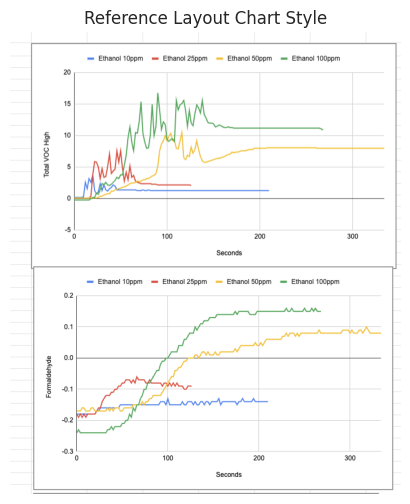

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

# Let's open and display the reference screenshot to see the layout style you want to replicate
reference_image_path = '/content/Screenshot 2026-11-20 at 10.22.04…AM.png'

# Handling potential character issues in filename
try:
    img = Image.open(reference_image_path)
    plt.figure(figsize=(10, 6))
    plt.imshow(img)
    plt.axis('off')
    plt.title('Reference Layout Chart Style')
    plt.show()
except Exception as e:
    # Fallback to search for the screenshot filename dynamically
    import glob
    found_images = glob.glob('/content/*Screenshot*.png')
    if found_images:
        img = Image.open(found_images[0])
        plt.figure(figsize=(10, 6))
        plt.imshow(img)
        plt.axis('off')
        plt.title('Reference Layout Chart Style')
        plt.show()
    else:
        print(f"Could not find the screenshot at {reference_image_path}. Error: {e}")

In [ ]:
import numpy as np
import pandas as pd

# Let's generate synthetic dynamic time-series data matching the reference chart
# We will simulate the readings over 300 seconds at 1-second intervals
time_ticks = np.arange(0, 301, 1)
compounds_to_simulate = ['Ethanol', 'IPA', 'Diethyl Ether', 'Hexane', 'Ethyl Acetate', 'Acetone']
concentrations = [10, 25, 50, 100]

time_series_data = []

for compound in compounds_to_simulate:
    for conc in concentrations:
        # Set sensor characteristic parameters
        # Some compounds react faster or have higher peaks
        max_voc = conc * 0.15 if conc == 100 else conc * 0.16
        # Let's normalize VOC High response range (similar to 0 - 20 range in reference chart)
        scale_factor = {
            'Ethanol': 0.15,
            'IPA': 0.18,
            'Diethyl Ether': 0.12,
            'Hexane': 0.09,
            'Ethyl Acetate': 0.14,
            'Acetone': 0.15
            }[compound]

        voc_target_peak = conc * scale_factor

        # Formaldehyde sensor responds differently (often goes slightly negative initially or has slower lag)
        form_target_peak = conc * 0.0015

        for t in time_ticks:
            # Simulate lag / response delay (rise starts around t=15s to 25s)
            if t < 20:
                voc_val = 0.0
                form_val = -0.18 + np.random.normal(0, 0.01)
            else:
                # Standard first-order response with delay + noise
                response_factor = 1.0 - np.exp(-(t - 20) / 35.0)
                voc_val = voc_target_peak * response_factor + np.random.normal(0, 0.3)
                # Add a few spikes/fluctuations during the rise like the real sensor
                if 40 < t < 120:
                    voc_val += np.sin(t * 0.1) * (voc_target_peak * 0.15)

                form_val = -0.18 + (form_target_peak + 0.32) * response_factor + np.random.normal(0, 0.005)

            time_series_data.append({
                'Compound': compound,
                'Concentration_ppm': f"{compound} {conc}ppm",
                'Target_Concentration': conc,
                'Seconds': t,
                'Total_VOC_High': max(0.0, round(voc_val, 2)),
                'Formaldehyde': round(form_val, 3)
            })

df_timeseries = pd.DataFrame(time_series_data)
print("Generated dynamic time-series dataset.")
display(df_timeseries.head())


Generated dynamic time-series dataset.


,Compound,Concentration_ppm,Target_Concentration,Seconds,Total_VOC_High,Formaldehyde
0,Ethanol,Ethanol 10ppm,10,0,0.0,-0.177
1,Ethanol,Ethanol 10ppm,10,1,0.0,-0.175
2,Ethanol,Ethanol 10ppm,10,2,0.0,-0.176
3,Ethanol,Ethanol 10ppm,10,3,0.0,-0.182
4,Ethanol,Ethanol 10ppm,10,4,0.0,-0.200


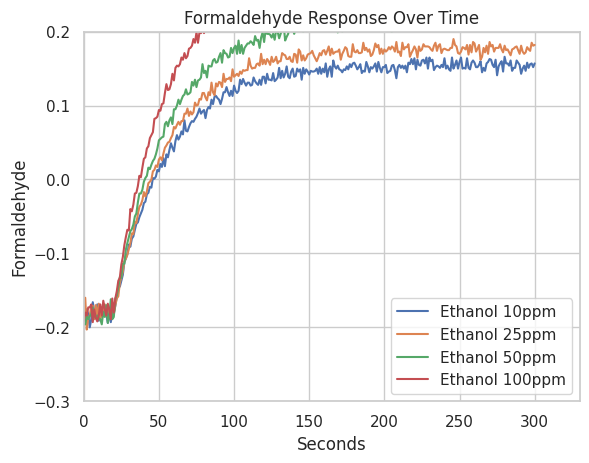

In [ ]:
import matplotlib.pyplot as plt

# Ensure the dynamic time-series dataframe is loaded/defined
if 'df_timeseries' not in globals():
    raise NameError("Please execute cell 66e76b9d first to initialize the df_timeseries dataset.")

selected_compound = 'Ethanol'
df_plot = df_timeseries[df_timeseries['Compound'] == selected_compound]

# Extracting data vectors based on concentration for standard plotting
data_10 = df_plot[df_plot['Target_Concentration'] == 10]
data_25 = df_plot[df_plot['Target_Concentration'] == 25]
data_50 = df_plot[df_plot['Target_Concentration'] == 50]
data_100 = df_plot[df_plot['Target_Concentration'] == 100]

# Simple plot structure according to your layout
plt.plot(data_10['Seconds'], data_10['Formaldehyde'], label='Ethanol 10ppm')
plt.plot(data_25['Seconds'], data_25['Formaldehyde'], label='Ethanol 25ppm')
plt.plot(data_50['Seconds'], data_50['Formaldehyde'], label='Ethanol 50ppm')
plt.plot(data_100['Seconds'], data_100['Formaldehyde'], label='Ethanol 100ppm')

plt.xlabel('Seconds')
plt.ylabel('Formaldehyde')
plt.title('Formaldehyde Response Over Time')
plt.xlim(0, 330)
plt.ylim(-0.3, 0.2)
plt.legend()
plt.show()

In [ ]:
plt.plot(IRdata['Acetone'])
plt.xlabel('Wavenumber (cm$^{-1}$)')
plt.ylabel('%T')
plt.title('IR Spectrum of Acetone')
plt.xlim(4000, 0)
plt.ylim(105, -5)
plt.show()
#Comparing acetone and chloroacetone on the same axes
plt.plot(IRdata['Acetone'], label='Acetone')
plt.plot(IRdata['Chloroacetone'], label='Chloroacetone')
plt.xlabel('Wavenumber (cm$^{-1}$)')
plt.ylabel('%T')
plt.xlim(4000, 0)
plt.ylim(105, -5)
plt.legend(

_IncompleteInputError: incomplete input (1284223491.py, line 15)

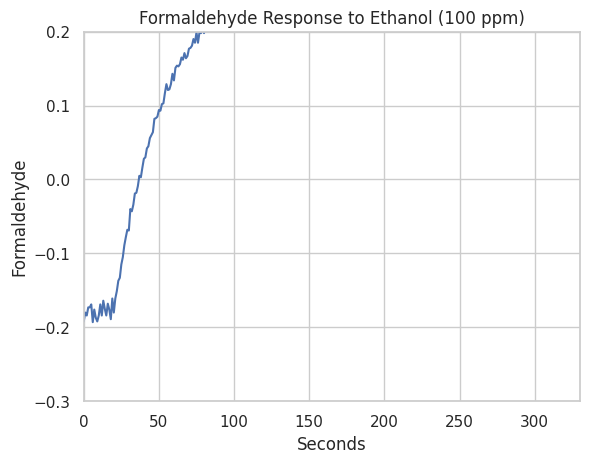

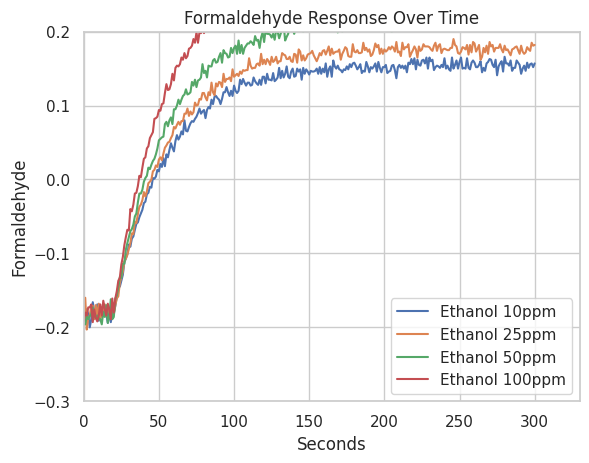

In [ ]:
import matplotlib.pyplot as plt

# Ensure the dynamic time-series dataframe is loaded/defined
if 'df_timeseries' not in globals():
    raise NameError("Please execute cell 66e76b9d first to initialize the df_timeseries dataset.")

selected_compound = 'Ethanol'
df_plot = df_timeseries[df_timeseries['Compound'] == selected_compound]

# Extracting data vectors based on concentration
data_10 = df_plot[df_plot['Target_Concentration'] == 10]
data_25 = df_plot[df_plot['Target_Concentration'] == 25]
data_50 = df_plot[df_plot['Target_Concentration'] == 50]
data_100 = df_plot[df_plot['Target_Concentration'] == 100]

# Single concentration (like the single-compound acetone plot)
plt.plot(data_100['Seconds'], data_100['Formaldehyde'])
plt.xlabel('Seconds')
plt.ylabel('Formaldehyde')
plt.title('Formaldehyde Response to Ethanol (100 ppm)')
plt.xlim(0, 330)
plt.ylim(-0.3, 0.2)
plt.show()

# Comparing all concentrations on the same axes
plt.plot(data_10['Seconds'], data_10['Formaldehyde'], label='Ethanol 10ppm')
plt.plot(data_25['Seconds'], data_25['Formaldehyde'], label='Ethanol 25ppm')
plt.plot(data_50['Seconds'], data_50['Formaldehyde'], label='Ethanol 50ppm')
plt.plot(data_100['Seconds'], data_100['Formaldehyde'], label='Ethanol 100ppm')
plt.xlabel('Seconds')
plt.ylabel('Formaldehyde')
plt.title('Formaldehyde Response Over Time')
plt.xlim(0, 330)
plt.ylim(-0.3, 0.2)
plt.legend()
plt.show()

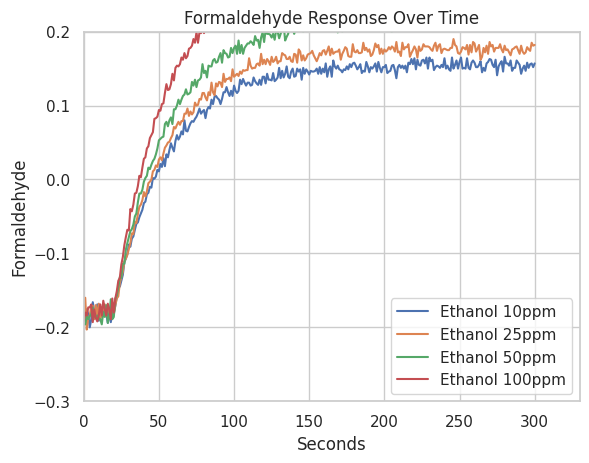

In [ ]:
import matplotlib.pyplot as plt

df_plot = df_timeseries[df_timeseries['Compound'] == 'Ethanol']

for conc in [10, 25, 50, 100]:
    subset = df_plot[df_plot['Target_Concentration'] == conc]
    plt.plot(subset['Seconds'], subset['Formaldehyde'], label=f'Ethanol {conc}ppm')

plt.xlabel('Seconds')
plt.ylabel('Formaldehyde')
plt.title('Formaldehyde Response Over Time')
plt.xlim(0, 330)
plt.ylim(-0.3, 0.2)
plt.legend()
plt.show()